# Spateo colon layer/column digitization

This notebook digitizes the colon spatial coordinates using Spateo's layer/column heat-equation workflow. It saves the continuous layer and column coordinates to `../data/spateo_colon_digitized.csv`.

In [1]:
import os
import warnings
from pathlib import Path

# Keep Spateo/Numba/Matplotlib cache writes in a writable location.
os.environ.setdefault("XDG_CACHE_HOME", "/private/tmp/cache-spateo")
os.environ.setdefault("MPLCONFIGDIR", "/private/tmp/mpl-spateo")
os.environ.setdefault("NUMBA_CACHE_DIR", "/private/tmp/numba-spateo")

import anndata as ad
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import spateo as st
from spateo.digitization.grid import digitize, gridit

warnings.filterwarnings("ignore", category=FutureWarning, module="spateo.digitization.grid")

plt.rcParams["figure.dpi"] = 120

Matplotlib is building the font cache; this may take a moment.
/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/spateo/get_version.py:104: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


fastpd is not installed. Please compile the fastpd library.


/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/numba/np/ufunc/dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
  warnings.warn(msg, errors.NumbaWarning)
/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/numba/np/ufunc/dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
  warnings.warn(msg, errors.NumbaWarning)
/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/numba/np/ufunc/dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a b

In [2]:
data_dir = Path("../data")
coords = np.load(data_dir / "coords_mat.npy", allow_pickle=True).astype(float)

adata = ad.AnnData(X=np.ones((coords.shape[0], 1)))
adata.obs_names = [f"spot_{i}" for i in range(coords.shape[0])]
adata.var_names = ["dummy"]
adata.obsm["spatial"] = coords
adata.obs["xcoord"] = coords[:, 0]
adata.obs["ycoord"] = coords[:, 1]

# Required by Spateo's type checker for digitize/gridit.
adata.uns["__type"] = "UMI"

print(adata)
pd.DataFrame(coords, columns=["xcoord", "ycoord"]).describe()

AnnData object with n_obs × n_vars = 7209 × 1
    obs: 'xcoord', 'ycoord'
    uns: '__type'
    obsm: 'spatial'


,xcoord,ycoord
count,7209.000000,7209.000000
mean,8699.128437,-578.052937
std,351.992267,603.771002
min,8124.294980,-1665.347140
25%,8374.290240,-1124.100336
50%,8658.535232,-578.982965
75%,9060.633018,21.153986
max,9344.126569,388.975869


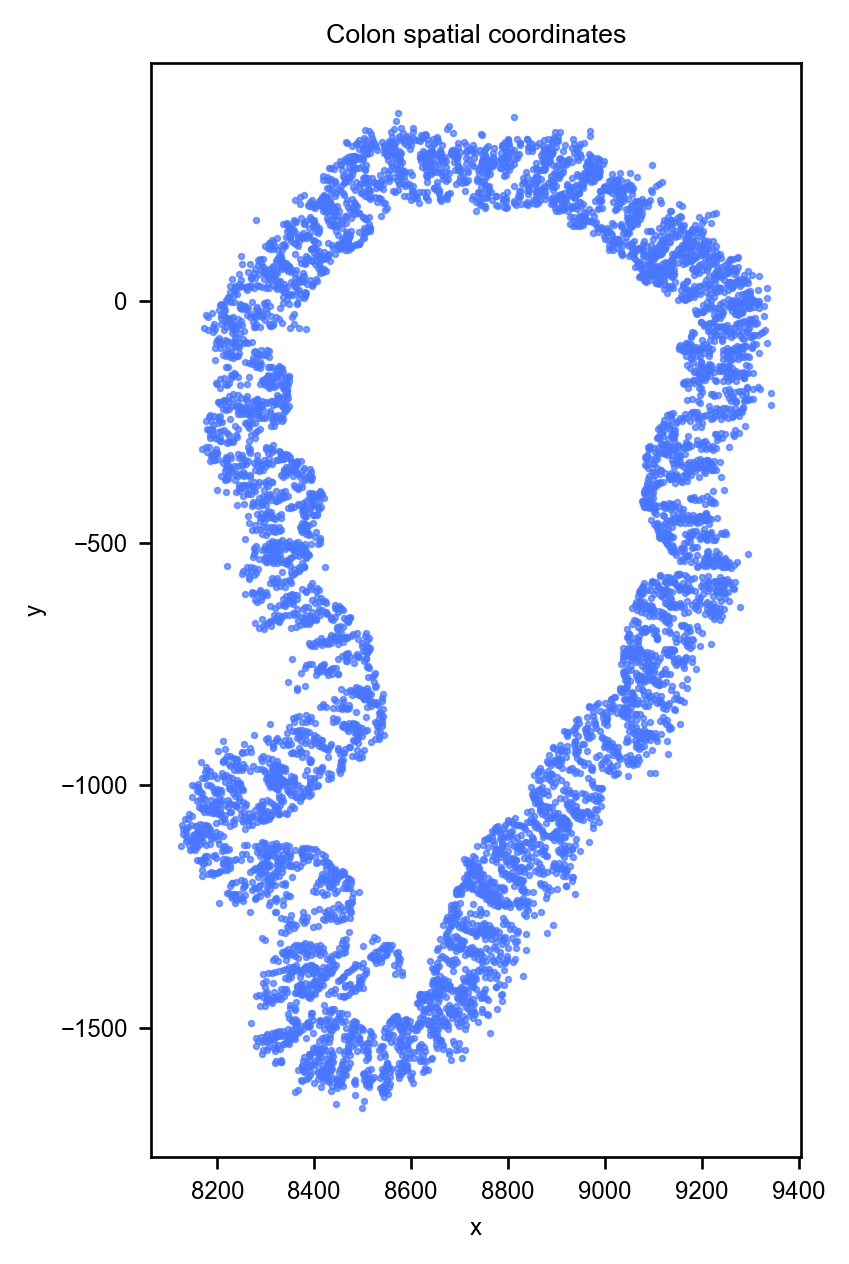

In [3]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(coords[:, 0], coords[:, 1], s=3, alpha=0.7)
ax.set_aspect("equal")
ax.set_title("Colon spatial coordinates")
ax.set_xlabel("x")
ax.set_ylabel("y")
plt.show()

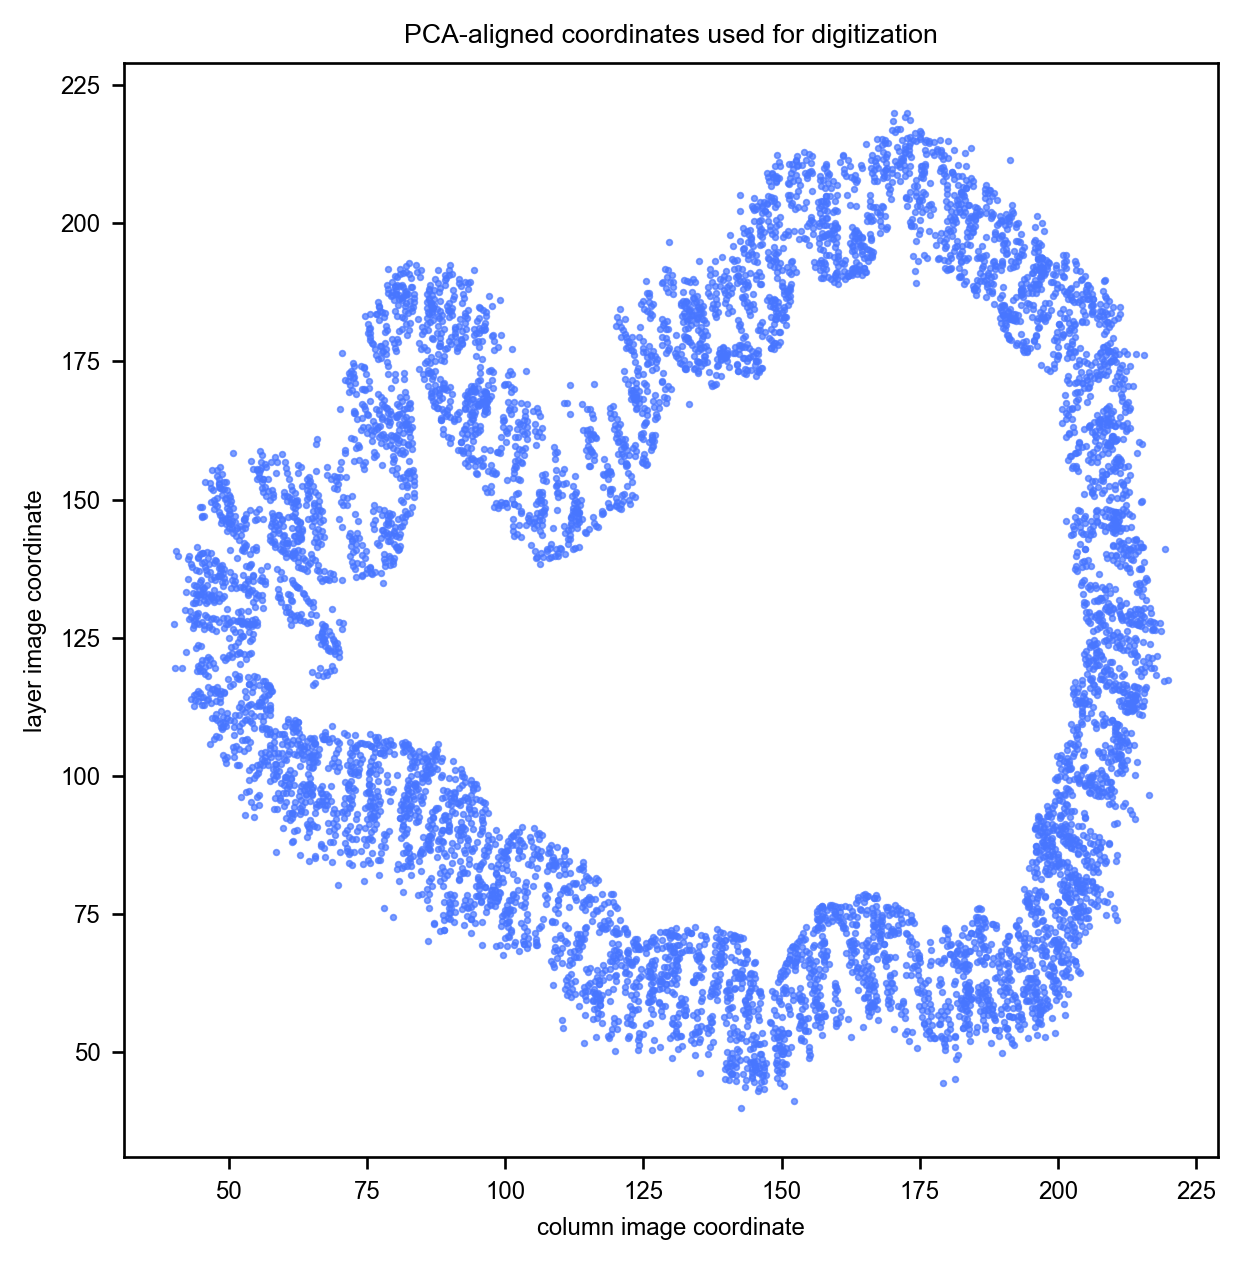

In [4]:
# Spateo's digitize() expects image-like coordinates and four ROI corner points.
# We create a PCA-aligned coordinate system:
#   column = first PC, the long axis of the tissue
#   layer  = second PC, the radial/depth axis of the tissue
#
# Flip either coordinate if the diagnostic plots show the opposite orientation.
center = coords.mean(axis=0)
coords_centered = coords - center
_, _, vt = np.linalg.svd(coords_centered, full_matrices=False)

column_axis = vt[0]
layer_axis = vt[1]

column_score = coords_centered @ column_axis
layer_score = coords_centered @ layer_axis

flip_column = False
flip_layer = False

if flip_column:
    column_score = -column_score
if flip_layer:
    layer_score = -layer_score

def normalize01(x):
    x = np.asarray(x, dtype=float)
    rng = x.max() - x.min()
    if rng == 0:
        return np.zeros_like(x)
    return (x - x.min()) / rng

column01 = normalize01(column_score)
layer01 = normalize01(layer_score)

# Use a compact image grid so the PDE solve is fast. The two axes use the same
# scale so Spateo sees a roughly isotropic pixel grid.
digitize_pad = 40
digitize_scale = 180
column_img = digitize_pad + digitize_scale * column01
layer_img = digitize_pad + digitize_scale * layer01

# Important: Spateo indexes fields as field[row, col], while OpenCV contours are
# represented as x=col, y=row. Keep both conventions explicit.
spatial_digitize = np.column_stack([layer_img, column_img])
contour_digitize = np.column_stack([column_img, layer_img])

adata.obsm["spatial_digitize"] = spatial_digitize
adata.obs["pca_column_score"] = column_score
adata.obs["pca_layer_score"] = layer_score

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(column_img, layer_img, s=3, alpha=0.7)
ax.set_aspect("equal")
ax.set_title("PCA-aligned coordinates used for digitization")
ax.set_xlabel("column image coordinate")
ax.set_ylabel("layer image coordinate")
plt.show()

In [5]:
# Build the ROI contour from the transformed point cloud. Increase point_radius
# or close_kernel_size if the contour is fragmented.
point_radius = 4
close_kernel_size = 13

img_size = int(np.ceil(max(contour_digitize.max(), spatial_digitize.max()))) + digitize_pad + 2
roi_img = np.zeros((img_size, img_size), dtype=np.uint8)

for col, row in np.round(contour_digitize).astype(int):
    cv2.circle(roi_img, (int(col), int(row)), point_radius, 255, -1)

kernel = np.ones((close_kernel_size, close_kernel_size), np.uint8)
roi_img_closed = cv2.morphologyEx(roi_img, cv2.MORPH_CLOSE, kernel)

contours, hierarchy = cv2.findContours(
    roi_img_closed,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_NONE,
)

if len(contours) == 0:
    raise RuntimeError("No ROI contour found. Increase point_radius or close_kernel_size.")

areas = np.array([cv2.contourArea(c) for c in contours])
ctr_idx = int(np.argmax(areas))

# digitize() allocates its field from max(adata.obsm[spatial_key]). Keep the
# contour vertices inside that field.
field_rowmax = int(np.floor(spatial_digitize[:, 0].max()))
field_colmax = int(np.floor(spatial_digitize[:, 1].max()))
contours = tuple(
    np.stack(
        [
            np.clip(c[:, :, 0], 0, field_colmax),
            np.clip(c[:, :, 1], 0, field_rowmax),
        ],
        axis=2,
    ).astype(np.int32)
    for c in contours
)

print(f"Found {len(contours)} contours. Using contour {ctr_idx} with area {areas[ctr_idx]:.1f}.")

Found 1 contours. Using contour 0 with area 24455.5.


Spateo corner points on contour, with nearest original spot index:
  pnt_xy: point=(59, 82), spot_idx=5948, original_xy=[ 8762.688025 -1510.31387 ]
  pnt_xY: point=(76, 194), spot_idx=379, original_xy=[ 8124.29498    -1125.86065231]
  pnt_Xy: point=(203, 51), spot_idx=7107, original_xy=[9335.83038462   26.72958158]
  pnt_XY: point=(195, 211), spot_idx=3585, original_xy=[8280.47152941  167.03160529]


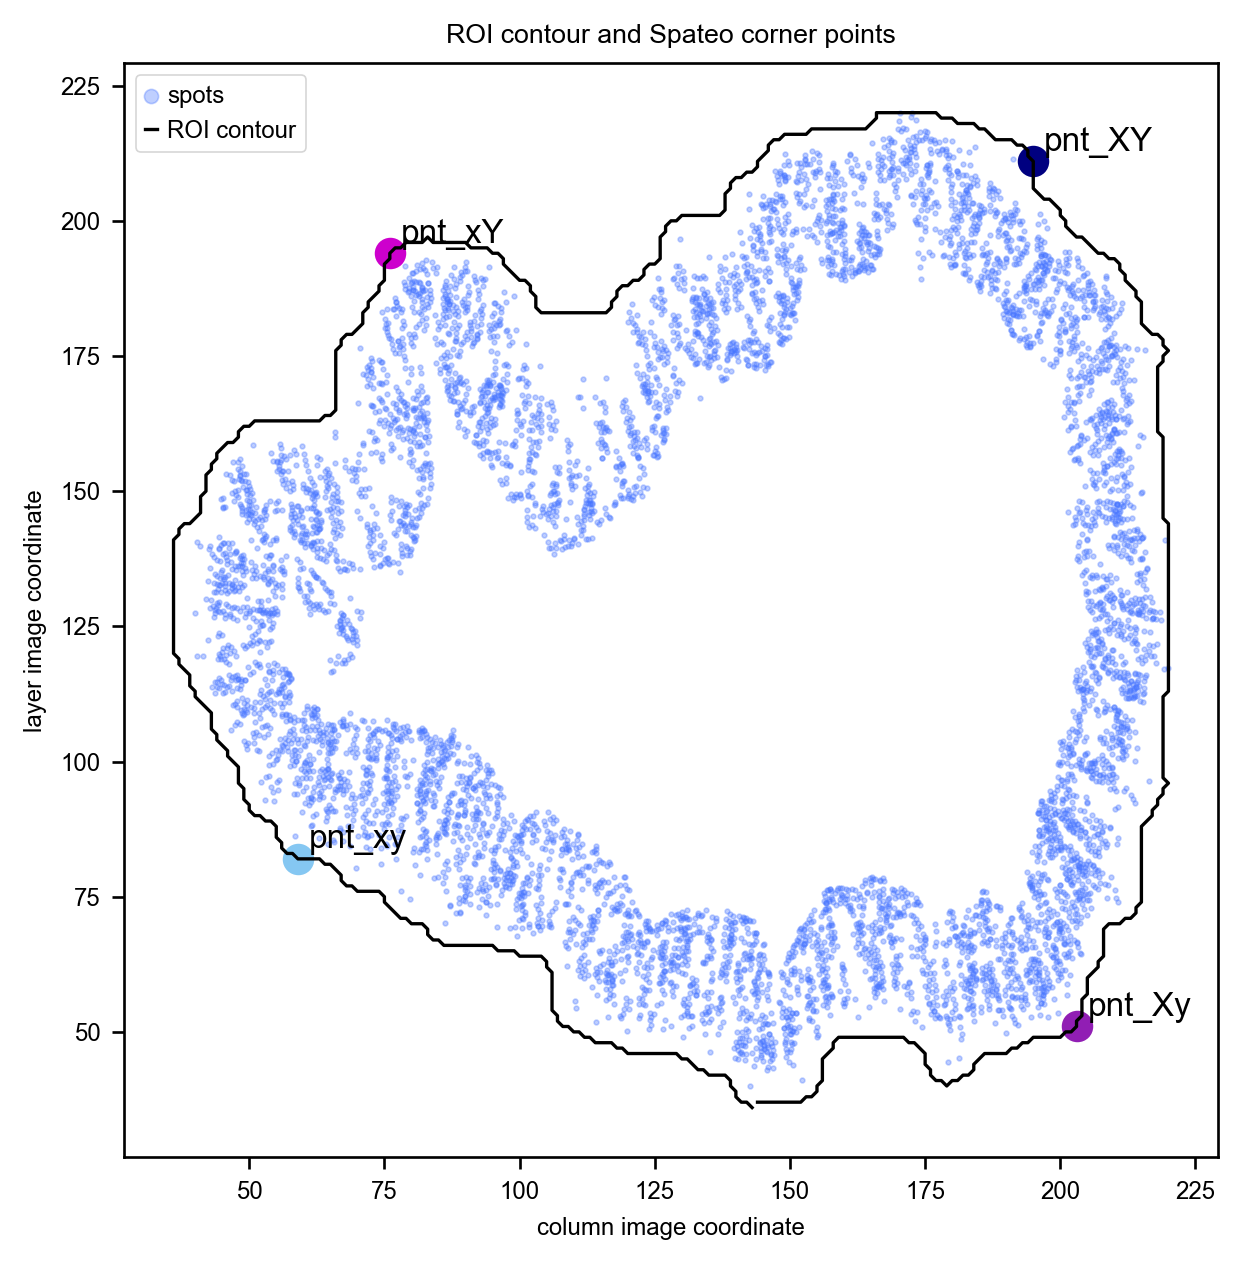

In [6]:
# Choose the four Spateo corner points automatically from the contour.
# Convention from Spateo:
#   pnt_xy = min layer, min column
#   pnt_xY = max layer, min column
#   pnt_Xy = min layer, max column
#   pnt_XY = max layer, max column
#
# Optional manual override: set these to zero-based spot indices if you want to
# force particular anchor spots, then re-run this cell and below.
manual_corner_rows = {
    "pnt_xy": None,
    "pnt_xY": None,
    "pnt_Xy": None,
    "pnt_XY": None,
}

contour = contours[ctr_idx][:, 0, :]
contour_min = contour.min(axis=0)
contour_max = contour.max(axis=0)
contour01 = (contour - contour_min) / (contour_max - contour_min)

def nearest_contour_corner(column_target, layer_target):
    d2_contour = (contour01[:, 0] - column_target) ** 2 + (contour01[:, 1] - layer_target) ** 2
    contour_vertex = int(np.argmin(d2_contour))
    point = tuple(map(int, contour[contour_vertex]))

    d2_spot = (contour_digitize[:, 0] - point[0]) ** 2 + (contour_digitize[:, 1] - point[1]) ** 2
    spot_idx = int(np.argmin(d2_spot))
    return point, spot_idx

def snap_spot_to_contour(row_idx):
    row_idx = int(row_idx)
    if row_idx < 0 or row_idx >= coords.shape[0]:
        raise IndexError(f"Corner row {row_idx} is outside the coordinate matrix.")
    anchor = contour_digitize[row_idx]
    d2_contour = (contour[:, 0] - anchor[0]) ** 2 + (contour[:, 1] - anchor[1]) ** 2
    contour_vertex = int(np.argmin(d2_contour))
    point = tuple(map(int, contour[contour_vertex]))
    return point, row_idx

auto_corners = {
    "pnt_xy": nearest_contour_corner(0, 0),
    "pnt_xY": nearest_contour_corner(0, 1),
    "pnt_Xy": nearest_contour_corner(1, 0),
    "pnt_XY": nearest_contour_corner(1, 1),
}

corner_points = {}
corner_indices = {}
for name, auto_value in auto_corners.items():
    if manual_corner_rows[name] is None:
        point, spot_idx = auto_value
    else:
        point, spot_idx = snap_spot_to_contour(manual_corner_rows[name])
    corner_points[name] = point
    corner_indices[name] = spot_idx

pnt_xy = corner_points["pnt_xy"]
pnt_xY = corner_points["pnt_xY"]
pnt_Xy = corner_points["pnt_Xy"]
pnt_XY = corner_points["pnt_XY"]

print("Spateo corner points on contour, with nearest original spot index:")
for name in ["pnt_xy", "pnt_xY", "pnt_Xy", "pnt_XY"]:
    idx = corner_indices[name]
    print(f"  {name}: point={corner_points[name]}, spot_idx={idx}, original_xy={coords[idx]}")

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(contour_digitize[:, 0], contour_digitize[:, 1], s=2, alpha=0.35, label="spots")
ax.plot(contour[:, 0], contour[:, 1], color="black", linewidth=1, label="ROI contour")

for name, point in corner_points.items():
    ax.scatter(point[0], point[1], s=80)
    ax.text(point[0] + 2, point[1] + 2, name, fontsize=10)

ax.set_aspect("equal")
ax.set_title("ROI contour and Spateo corner points")
ax.set_xlabel("column image coordinate")
ax.set_ylabel("layer image coordinate")
ax.legend(loc="best", markerscale=3)
plt.show()

In [7]:
# Run Spateo digitization. The raw values are heat-equation values on [lh, hh]
# for spots inside the ROI, with zeros usually indicating points outside the ROI.
digitize(
    adata=adata,
    ctrs=contours,
    ctr_idx=ctr_idx,
    pnt_xy=pnt_xy,
    pnt_xY=pnt_xY,
    pnt_Xy=pnt_Xy,
    pnt_XY=pnt_XY,
    spatial_key="spatial_digitize",
    dgl_layer_key="spateo_layer_raw",
    dgl_column_key="spateo_column_raw",
    max_itr=5000,
    lh=1,
    hh=100,
)

gridit(
    adata=adata,
    layer_num=10,
    column_num=10,
    dgl_layer_key="spateo_layer_raw",
    dgl_column_key="spateo_column_raw",
    layer_label_key="spateo_layer_label",
    column_label_key="spateo_column_label",
    grid_label_key="spateo_grid_label",
)

adata.obs["spateo_layer"] = normalize01(adata.obs["spateo_layer_raw"].astype(float).to_numpy())
adata.obs["spateo_column"] = normalize01(adata.obs["spateo_column_raw"].astype(float).to_numpy())

for key in ["spateo_layer_raw", "spateo_column_raw", "spateo_layer", "spateo_column"]:
    values = adata.obs[key].astype(float).to_numpy()
    print(f"{key}: zeros={(values == 0).sum()}, min={values.min():.4f}, max={values.max():.4f}")

|-----> Initialize the field of the spatial domain of interests.
|-----> Prepare the isoline segments with either the highest/lower column or layer heat values.
|-----> Solve the layer heat equation on spatial domain with the iso-layer-line conditions.
|-----> Max iteration reached, with L2 error at: 6.161630978848211e-05
|-----> Total iteration: 5001
|-----> Saving layer heat values to spateo_layer_raw.
spot_0       0.0
spot_1       0.0
spot_2       0.0
spot_3       0.0
spot_4       0.0
            ... 
spot_7204    0.0
spot_7205    0.0
spot_7206    0.0
spot_7207    0.0
spot_7208    0.0
Name: spateo_layer_raw, Length: 7209, dtype: float64
|-----> Solve the column heat equation on spatial domain with the iso-column-line conditions.
|-----> Max iteration reached, with L2 error at: 6.538077564210996e-05
|-----> Total iteration: 5001
|-----> Saving column heat values to spateo_column_raw.
|-----> Prepare spateo_layer_label, spateo_column_label and spateo_grid_label keys.
|-----> Set layer

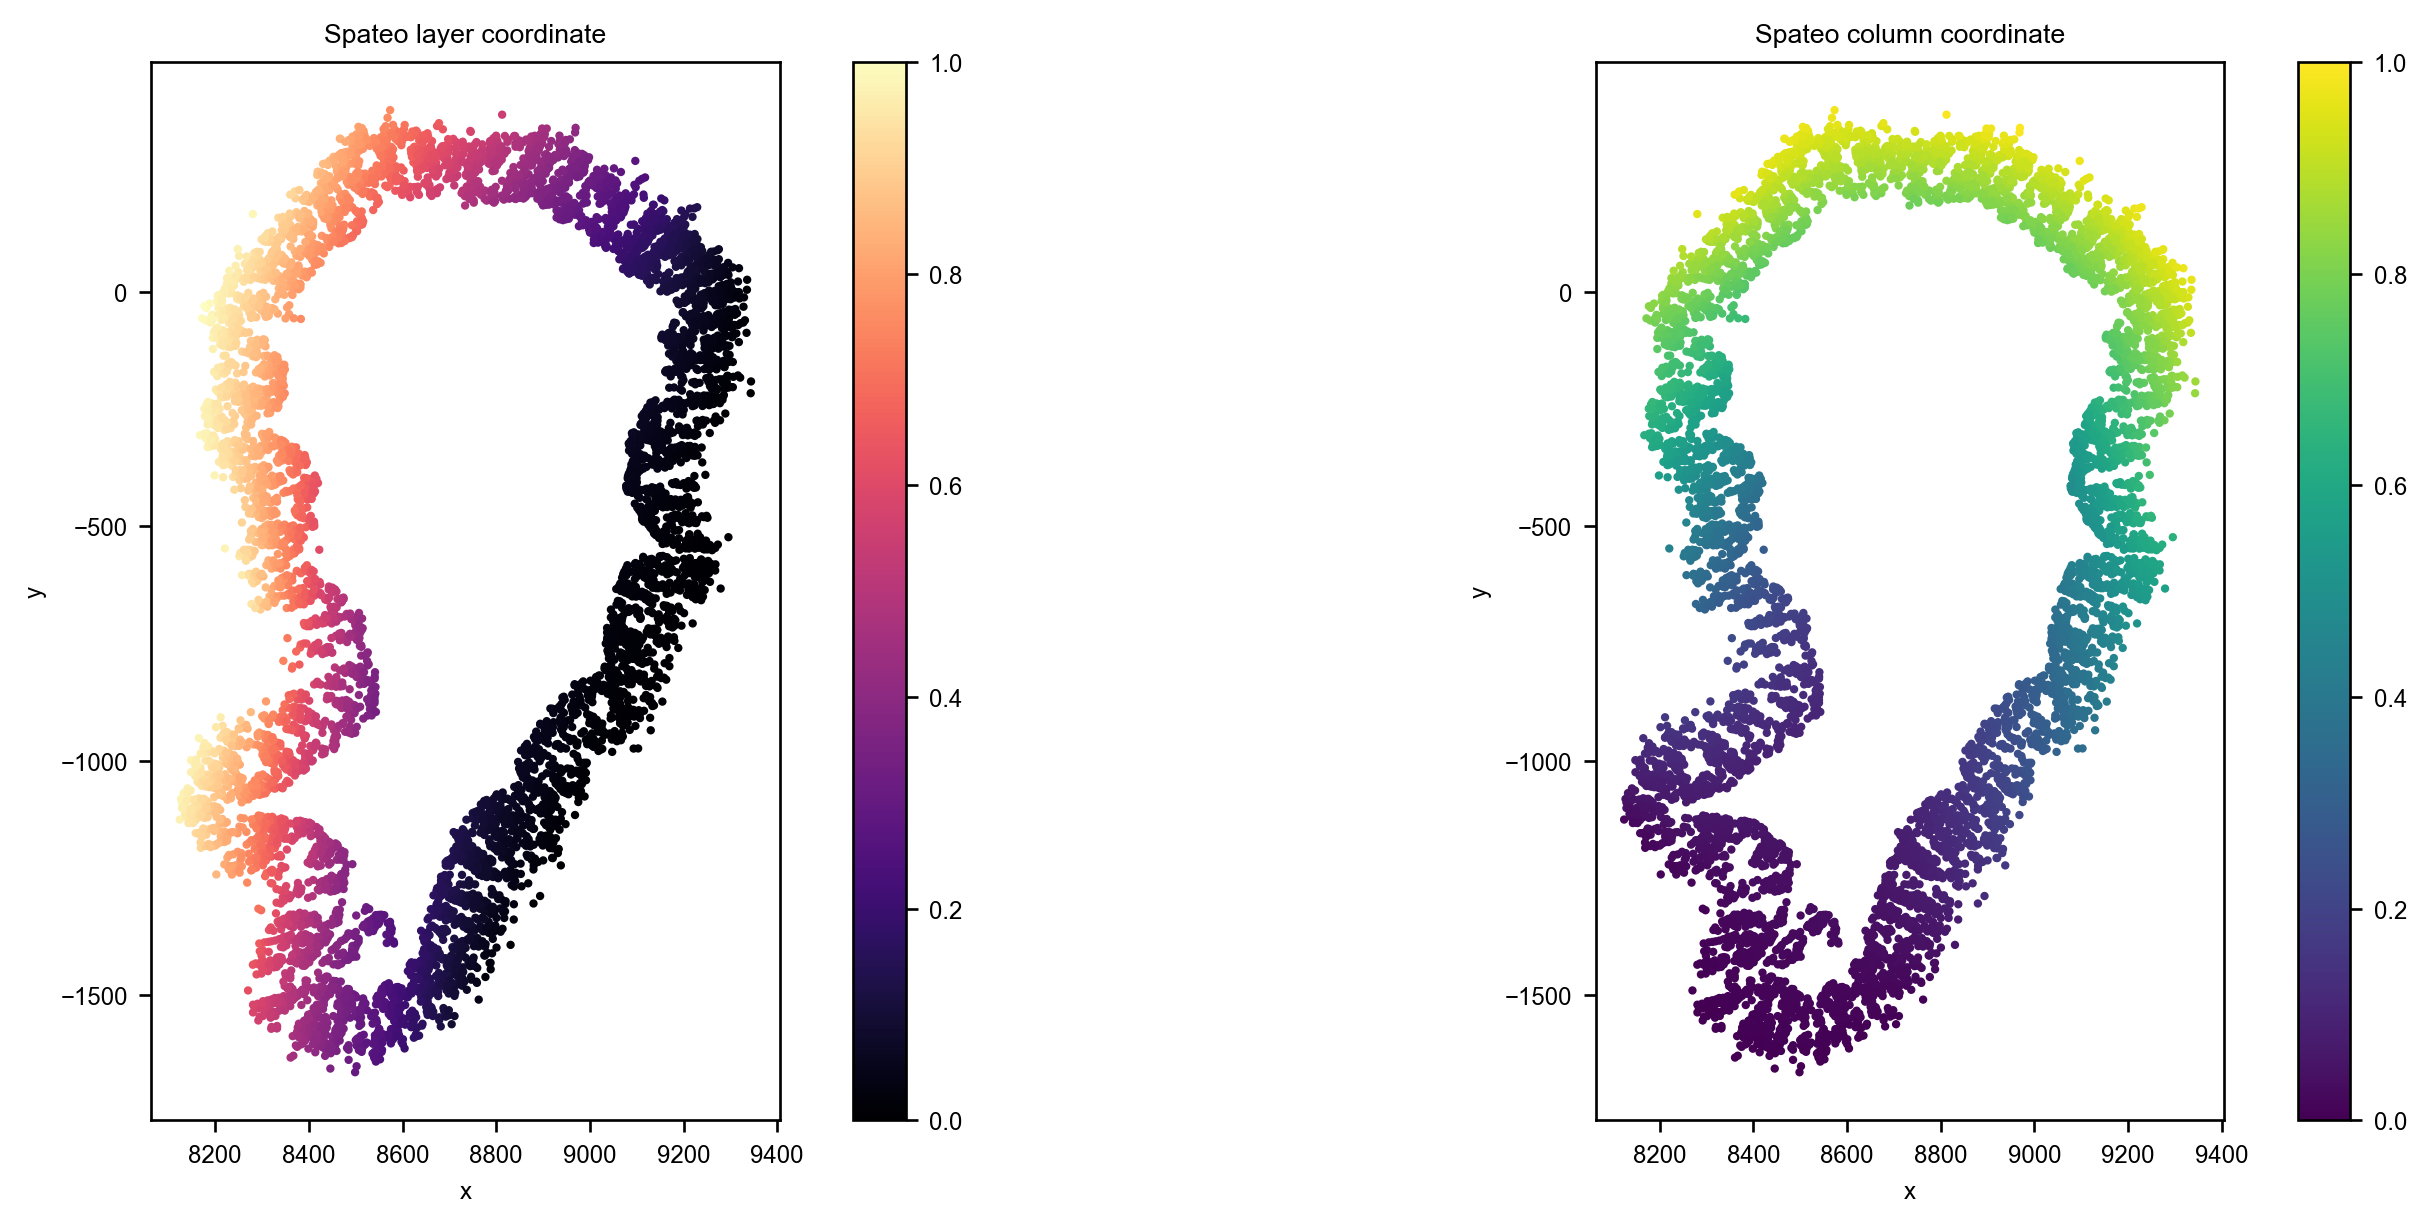

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

sc0 = axes[0].scatter(coords[:, 0], coords[:, 1], c=adata.obs["spateo_layer"], s=4, cmap="magma")
axes[0].set_title("Spateo layer coordinate")
axes[0].set_aspect("equal")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
plt.colorbar(sc0, ax=axes[0], fraction=0.046, pad=0.04)

sc1 = axes[1].scatter(coords[:, 0], coords[:, 1], c=adata.obs["spateo_column"], s=4, cmap="viridis")
axes[1].set_title("Spateo column coordinate")
axes[1].set_aspect("equal")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
plt.colorbar(sc1, ax=axes[1], fraction=0.046, pad=0.04)

plt.show()

In [10]:
digitized = pd.DataFrame(
    {
        "spot": adata.obs_names,
        "xcoord": coords[:, 0],
        "ycoord": coords[:, 1],
        "spateo_layer": adata.obs["spateo_layer"].astype(float).to_numpy(),
        "spateo_column": adata.obs["spateo_column"].astype(float).to_numpy(),
        "spateo_layer_raw": adata.obs["spateo_layer_raw"].astype(float).to_numpy(),
        "spateo_column_raw": adata.obs["spateo_column_raw"].astype(float).to_numpy(),
        "spateo_layer_label": adata.obs["spateo_layer_label"].to_numpy(),
        "spateo_column_label": adata.obs["spateo_column_label"].to_numpy(),
        "spateo_grid_label": adata.obs["spateo_grid_label"].to_numpy(),
        "pca_layer_score": layer_score,
        "pca_column_score": column_score,
    }
)

out_csv = data_dir / "spateo_colon_digitized.csv"
digitized.to_csv(out_csv, index=False)

print(f"Saved {out_csv.resolve()}")
digitized.head()

Saved /Users/phillipnicol/Documents/GitHub/morphoGAM-paper/analysis/python_models/data/spateo_colon_digitized.csv


,spot,xcoord,ycoord,spateo_layer,spateo_column,spateo_layer_raw,spateo_column_raw,spateo_layer_label,spateo_column_label,spateo_grid_label,pca_layer_score,pca_column_score
0,spot_0,8361.009263,-1634.084526,0.462462,0.000457,46.821275,1.170859,5,1,Region Boundary,97.191242,-1104.572839
1,spot_1,8292.090467,-1554.856980,0.569673,0.000076,57.427677,1.133183,6,1,Region Boundary,181.869406,-1042.472813
2,spot_2,8366.931964,-1630.056104,0.454228,0.000632,46.006679,1.188108,5,1,Region Boundary,92.301402,-1099.338715
3,spot_3,8280.761000,-1537.659326,0.586306,0.000000,59.073249,1.125646,6,1,Region Boundary,196.708882,-1028.193245
4,spot_4,8294.970543,-1546.486172,0.570640,0.000619,57.523424,1.186803,6,1,Region Boundary,180.903995,-1033.673197


In [ ]:
## Now run Spateo on the counts 

In [11]:
from spateo.tools.glm import glm_degs
import warnings

counts_mat = np.load(data_dir / "counts_mat.npy", allow_pickle=True)
gene_labels = np.load(data_dir / "gene_labels.npy", allow_pickle=True).astype(str)
digitized = pd.read_csv(data_dir / "spateo_colon_digitized.csv")

required_digitized_cols = ["xcoord", "ycoord", "spateo_layer", "spateo_column"]
missing_cols = [col for col in required_digitized_cols if col not in digitized.columns]
if missing_cols:
    raise ValueError(f"Missing columns in spateo_colon_digitized.csv: {missing_cols}")

# The colon counts used in gaston_colon_genes.ipynb are genes x spots.
# AnnData expects spots x genes.
if counts_mat.shape == (len(gene_labels), digitized.shape[0]):
    raw_counts = counts_mat.astype(float).T
elif counts_mat.shape == (digitized.shape[0], len(gene_labels)):
    raw_counts = counts_mat.astype(float)
else:
    raise ValueError(
        "Could not align counts_mat with gene_labels and digitized spots: "
        f"counts_mat={counts_mat.shape}, genes={len(gene_labels)}, spots={digitized.shape[0]}"
    )

# Spateo's glm_degs expects size-factor-normalized expression.
library_size = raw_counts.sum(axis=1)
median_library_size = np.median(library_size[library_size > 0])
size_factors = np.where(library_size > 0, library_size / median_library_size, 1.0)
normalized_counts = raw_counts / size_factors[:, None]

spot_names = digitized["spot"].astype(str).to_list() if "spot" in digitized.columns else [f"spot_{i}" for i in range(raw_counts.shape[0])]

obs = pd.DataFrame(
    {
        "xcoord": digitized["xcoord"].to_numpy(),
        "ycoord": digitized["ycoord"].to_numpy(),
        "layer": digitized["spateo_layer"].to_numpy(),
        "column": digitized["spateo_column"].to_numpy(),
        "size_factor": size_factors,
        "library_size": library_size,
    },
    index=spot_names,
)

adata_counts = ad.AnnData(
    X=normalized_counts,
    obs=obs,
    var=pd.DataFrame(index=gene_labels),
)
adata_counts.layers["counts"] = raw_counts
adata_counts.obsm["spatial"] = digitized[["xcoord", "ycoord"]].to_numpy()
adata_counts.var_names_make_unique()

print(adata_counts)
print(f"layer range: {adata_counts.obs['layer'].min():.4f} to {adata_counts.obs['layer'].max():.4f}")
print(f"column range: {adata_counts.obs['column'].min():.4f} to {adata_counts.obs['column'].max():.4f}")
display(adata_counts.obs[["xcoord", "ycoord", "layer", "column", "library_size"]].head())

AnnData object with n_obs × n_vars = 7209 × 694
    obs: 'xcoord', 'ycoord', 'layer', 'column', 'size_factor', 'library_size'
    obsm: 'spatial'
    layers: 'counts'
layer range: 0.0000 to 1.0000
column range: 0.0000 to 1.0000


,xcoord,ycoord,layer,column,library_size
spot_0,8361.009263,-1634.084526,0.462462,0.000457,14.0
spot_1,8292.090467,-1554.856980,0.569673,0.000076,29.0
spot_2,8366.931964,-1630.056104,0.454228,0.000632,22.0
spot_3,8280.761000,-1537.659326,0.586306,0.000000,54.0
spot_4,8294.970543,-1546.486172,0.570640,0.000619,67.0


In [12]:
def run_spateo_glm(adata, key_added, full_formula, reduced_formula, top_n=25):
    """Run Spateo's GLM SVG test and return a q-value/p-value-ranked table."""
    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore",
            message="Negative binomial dispersion parameter alpha not set.*",
        )

        glm_degs(
            adata,
            key_added=key_added,
            fullModelFormulaStr=full_formula,
            reducedModelFormulaStr=reduced_formula,
            qval_threshold=None,
            llf_threshold=None,
            inplace=True,
        )

    hits = adata.uns[key_added]["glm_result"].copy()
    hits.insert(0, "gene", hits.index)

    sort_cols = [col for col in ["qval", "pval"] if col in hits.columns]
    ascending = [True] * len(sort_cols)
    if "log-likelihood" in hits.columns:
        sort_cols.append("log-likelihood")
        ascending.append(False)

    hits = hits.sort_values(sort_cols, ascending=ascending).reset_index(drop=True)
    hits.insert(0, "spateo_rank", np.arange(1, hits.shape[0] + 1))

    print(f"{key_added}: full={full_formula}, reduced={reduced_formula}")
    display(hits.head(top_n))
    print(hits.head(top_n).to_string(index=False))

    return hits

In [13]:
# Overall spatial SVG test using both Spateo digitization coordinates.
# This ranks genes by whether adding smooth layer and column effects improves the GLM.
spateo_svg_hits = run_spateo_glm(
    adata_counts,
    key_added="glm_degs_layer_column",
    full_formula="~cr(layer, df=9)",
    reduced_formula="~1",
)

spateo_svg_hits.to_csv(data_dir / "spateo_colon_svg_rankings.csv", index=False)
print(f"Saved {(data_dir / 'spateo_colon_svg_rankings.csv').resolve()}")

|-----? Gene expression matrix must be normalized by the size factor, please check if the input gene expression matrix is correct.If you don't have the size factor normalized gene expression matrix, please run `dynamo.pp.normalize_cell_expr_by_size_factors(skip_log = True)`.


/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/statsmodels/regression/_prediction.py:75: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(self.var_pred_mean)
/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/statsmodels/genmod/families/links.py:527: RuntimeWarning: overflow encountered in exp
  return np.exp(z)


|-----> [Detecting genes via Generalized Additive Models (GAMs)] in progress: 1.0086%

/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/statsmodels/regression/_prediction.py:75: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(self.var_pred_mean)
/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/statsmodels/genmod/families/links.py:527: RuntimeWarning: overflow encountered in exp
  return np.exp(z)
/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/statsmodels/regression/_prediction.py:75: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(self.var_pred_mean)
/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/statsmodels/genmod/families/links.py:527: RuntimeWarning: overflow encountered in exp
  return np.exp(z)
/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/statsmodels/regression/_prediction.py:75: RuntimeWarning: invalid value encountere

|-----> [Detecting genes via Generalized Additive Models (GAMs)] in progress: 2.0173%

...

/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/statsmodels/regression/_prediction.py:75: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(self.var_pred_mean)
/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/statsmodels/genmod/families/links.py:527: RuntimeWarning: overflow encountered in exp
  return np.exp(z)
/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/statsmodels/regression/_prediction.py:75: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(self.var_pred_mean)
/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/statsmodels/genmod/families/links.py:527: RuntimeWarning: overflow encountered in exp
  return np.exp(z)


|-----> [Detecting genes via Generalized Additive Models (GAMs)] in progress: 100.0000%
|-----> [Detecting genes via Generalized Additive Models (GAMs)] finished [93.6493s]
glm_degs_layer_column: full=~cr(layer, df=9), reduced=~1


/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/statsmodels/regression/_prediction.py:75: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(self.var_pred_mean)
/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/statsmodels/genmod/families/links.py:527: RuntimeWarning: overflow encountered in exp
  return np.exp(z)
/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/statsmodels/regression/_prediction.py:75: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(self.var_pred_mean)
/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/statsmodels/genmod/families/links.py:527: RuntimeWarning: overflow encountered in exp
  return np.exp(z)
/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/statsmodels/stats/multitest.py:350: RuntimeWarning: invalid value encountered in l

,spateo_rank,gene,status,family,log-likelihood,pval,qval
0,1,Ddx58,ok,NB2,-1929.582031,0.000000e+00,0.000000e+00
1,2,Dhx58,ok,NB2,-3950.830811,0.000000e+00,0.000000e+00
2,3,Vegfa,ok,NB2,-4273.966309,0.000000e+00,0.000000e+00
3,4,Ptprr,ok,NB2,-5154.296875,0.000000e+00,0.000000e+00
4,5,Ifih1,ok,NB2,-5398.258789,0.000000e+00,0.000000e+00
5,6,Nt5e,ok,NB2,-5449.044922,0.000000e+00,0.000000e+00
6,7,Bmp2,ok,NB2,-5746.905762,0.000000e+00,0.000000e+00
7,8,Ephb4,ok,NB2,-5898.864746,0.000000e+00,0.000000e+00
8,9,Celsr1,ok,NB2,-6936.322266,0.000000e+00,0.000000e+00
9,10,Il22ra1,ok,NB2,-8776.817383,0.000000e+00,0.000000e+00


 spateo_rank    gene status family  log-likelihood         pval         qval
           1   Ddx58     ok    NB2    -1929.582031 0.000000e+00 0.000000e+00
           2   Dhx58     ok    NB2    -3950.830811 0.000000e+00 0.000000e+00
           3   Vegfa     ok    NB2    -4273.966309 0.000000e+00 0.000000e+00
           4   Ptprr     ok    NB2    -5154.296875 0.000000e+00 0.000000e+00
           5   Ifih1     ok    NB2    -5398.258789 0.000000e+00 0.000000e+00
           6    Nt5e     ok    NB2    -5449.044922 0.000000e+00 0.000000e+00
           7    Bmp2     ok    NB2    -5746.905762 0.000000e+00 0.000000e+00
           8   Ephb4     ok    NB2    -5898.864746 0.000000e+00 0.000000e+00
           9  Celsr1     ok    NB2    -6936.322266 0.000000e+00 0.000000e+00
          10 Il22ra1     ok    NB2    -8776.817383 0.000000e+00 0.000000e+00
          11  Scnn1a     ok    NB2   -13692.584961 0.000000e+00 0.000000e+00
          12   Erbb3     ok    NB2   -16486.978516 0.000000e+00 0.000000e+00

In [ ]:
# Coordinate-specific tests. These are useful if you want to know whether a gene is
# associated with layer after controlling for column, or column after controlling for layer.
spateo_layer_hits = run_spateo_glm(
    adata_counts,
    key_added="glm_degs_layer_given_column",
    full_formula="~cr(layer, df=5) + cr(column, df=9)",
    reduced_formula="~cr(column, df=9)",
)

spateo_column_hits = run_spateo_glm(
    adata_counts,
    key_added="glm_degs_column_given_layer",
    full_formula="~cr(layer, df=5) + cr(column, df=9)",
    reduced_formula="~cr(layer, df=5)",
)

spateo_layer_hits.to_csv(data_dir / "spateo_colon_layer_rankings.csv", index=False)
spateo_column_hits.to_csv(data_dir / "spateo_colon_column_rankings.csv", index=False)

print(f"Saved {(data_dir / 'spateo_colon_layer_rankings.csv').resolve()}")
print(f"Saved {(data_dir / 'spateo_colon_column_rankings.csv').resolve()}")